<font size = 3 color="gray">Máster Universitario en inteligencia artificial (MUIA)</font> 

# Red neuronal sencilla

Red neuronal para aprender los distintos pasos del aprendizaje.
La red consiste en una capa de entrada de dos neuronas, una capa oculta de tres neuronas con función de activación sigmoidea o ReLU 
y una capa de salida con función sigmoidea.


In [94]:
%config InlineBackend.figure_format = 'retina'
import matplotlib.pyplot as plt
import numpy as np
import copy
import random

In [95]:
def random_init(longitud):
    """Devuelve un array de 'longitud' valores aleatorios con distribución N(0,1)."""
    return (np.random.randn(longitud))

def crea_datos(numpuntos):
    """Genera numpuntos muestras (x, y) aleatorias """
    inputs = [np.array(np.random.rand(numpuntos))]  # Fila 0, valores x
    inputs.append(np.random.rand(numpuntos))        # Fila 1, valores y   
    inputs.append(np.zeros(numpuntos))              # Fila 2, etiquetas
    for i in range(numpuntos):
        inputs[2][i] = ((inputs[1][i]**2+inputs[0][i]**2)<0.7**2) # or (inputs[0][i]>0.9)
        #inputs[2][i] = ((inputs[1][i]+inputs[0][i])<1)
    return inputs

In [96]:
def plot_data(data, plabels=""):
    """Dibuja los puntos del conjunto de datos coloreados por clase.
    Si se pasan plabels (predicciones), colorea según ellas: azul=0, verde=1, rojo=error."""
    fig = plt.figure(figsize=(5,5))
    ax = fig.add_subplot(111)
    cols=["blue","green","red"]
    for v in range(3):
        dplot = data[data[:,2]==v]
        if len(plabels)==0:
            pass 
        else:
            dplot = data[plabels==v]
        ax.scatter(dplot[:,0], dplot[:,1], color=cols[v], s=10,  zorder=50)
    nudge = 0.02
    ax.set_aspect('equal', 'datalim')
    plt.show()
    return

In [97]:
NUM_PUNTOS_ALL = 10000
NUM_PUNTOS_TRAIN = round(0.8*NUM_PUNTOS_ALL)
NUM_PUNTOS_TEST = NUM_PUNTOS_ALL - NUM_PUNTOS_TRAIN

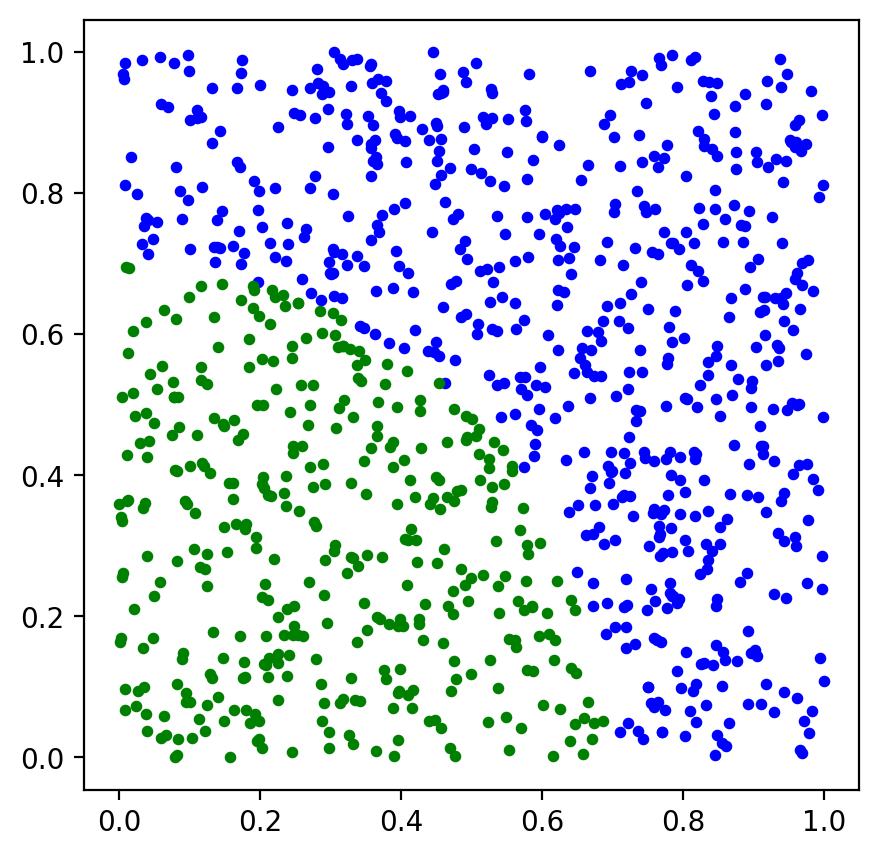

In [98]:
train_samples = crea_datos(NUM_PUNTOS_TRAIN)
datos=[[train_samples[0][i],train_samples[1][i],train_samples[2][i]] for i in range(NUM_PUNTOS_TRAIN)]
datos=np.array(datos).reshape(NUM_PUNTOS_TRAIN,3)
labels=np.array(train_samples[2:])
numpuntosplot=round(NUM_PUNTOS_ALL/10)
plot_data(datos[0:numpuntosplot])
test_samples = crea_datos(NUM_PUNTOS_TEST)

La red consiste en una capa de entrada de dos neuronas, una capa oculta de tres neuronas con función de activación sigmoidea o ReLU y una capa de salida con función sigmoidea.

In [99]:
def create_void_cols(dim):
    """Crea una lista de vectores de ceros. Cada elemento de 'dim' indica el tamaño
    del vector correspondiente. Se usa para inicializar activaciones, deltas y gradientes."""
    vcol = list()
    for i in dim:
        vcol.append( np.zeros(i,dtype=np.float64))
    return(vcol)

In [100]:
cost_train=np.zeros(NUM_PUNTOS_TRAIN)
learning_rate = 0.2                       # Tasa de aprendizaje
a = create_void_cols([2,3,1])             # Tensor de activaciones
z=copy.deepcopy(a)                        # Tensor de sumas ponderadas
z[0][0]= -1                               # El elemento 0 se inicializa a -1 porque no tiene sentido
z[0][1]= -1
d=copy.deepcopy(a)

In [101]:
n0, n1, n2 = 2, 3, 1   # neuronas por capa

w = [np.array([0, 0])]
w.append(np.random.randn(n1, n0) * np.sqrt(2 / n0))   # He    — capa ReLU,     shape (3,2)
w.append(np.random.randn(n2, n1) * np.sqrt(1 / n1))   # Xavier — capa sigmoid, shape (1,3)

b = [np.array([0, 0])]
b.append(np.zeros(n1))
b.append(np.zeros(n2))

delta_l = create_void_cols([1,3,1])            # Errores de cada neurona, para la retropropagación
nabla_w = copy.deepcopy(w)                     # Gradientes de los pesos
nabla_b = [np.zeros(bs.shape) for bs in b]     # Gradientes de los sesgos

In [102]:
def sigmoid(z):
    """Función de activación sigmoide: comprime cualquier valor real al intervalo (0,1)."""
    return(1.0 / (1.0+np.exp(-1*z)))

def ReLU(z):
    """Función de activación ReLU: devuelve z si z>0, cero en caso contrario."""
    mdatos = copy.deepcopy(z)
    for i in np.arange(len(mdatos)):
        if mdatos[i]<0:
            mdatos[i] = 0
    return(mdatos)

def NN_procesar(mya, myb, w, function="sigmoid"):
    """Calcula la salida de una capa: primero la suma ponderada z = w·a + b,
    luego aplica la función de activación indicada ('sigmoid' o 'ReLU').
    Devuelve (z, activación(z))."""
    mz = np.dot(w, mya) + myb
    if (function=="sigmoid"):
        return(mz,sigmoid(mz))
    if (function=="ReLU"):
        return(mz,ReLU(mz))

In [103]:
def forward_prop(inp, b, w):
    """Propaga la entrada hacia adelante por las dos capas de la red:
    capa oculta con ReLU y capa de salida con sigmoid.
    Actualiza los tensores globales a (activaciones) y z (sumas ponderadas)."""
    global a,z
    z[1],a[1] = NN_procesar(inp,b[1],w[1],function="ReLU")
    z[2],a[2] = NN_procesar(a[1],b[2],w[2],function="sigmoid")
    return(z,a)

In [104]:
def evaluar_clasificacion(samples, num_puntos_sample):
    """Recorre todas las muestras, hace una predicción con la red actual (umbral 0.5)
    y devuelve el número de aciertos y la lista de predicciones."""
    global a
    aciertos = 0
    predicciones = []
    for i in range(num_puntos_sample):
        a[0][0] = samples[0][i]
        a[0][1] = samples[1][i]
        z,a = forward_prop(a[0],b,w)
        pred = float(a[-1][0]>0.5)
        predicciones.append(pred)
        aciertos += pred == samples[2][i]
    return(aciertos,predicciones)

In [105]:
# Evaluación del error de clasificación con los pesos aleatorios sobre el conjunto de entrenamiento
# Se usa solo como base para comparar
aciertos,predicciones = evaluar_clasificacion(train_samples, NUM_PUNTOS_TRAIN)
tasa_antes=(aciertos/NUM_PUNTOS_TRAIN)

In [106]:
tasa_antes

np.float64(0.387875)

In [107]:
### Fórmulas de backprop
# d^L   = Grad_a C . s'(z^L)
# d^l   = (w^(l+1))T . d^(l+1) . s'(z^l)
# Grad_bj C    = d_j^l
# Grad_w_jk^l  = d_j^l . a_k^(l-1)

def sigmoid_derivada(z):
    """Derivada de la sigmoide: σ'(z) = σ(z)·(1−σ(z)). Necesaria en backprop."""
    return(sigmoid(z)*(1-sigmoid(z)))

def ReLU_derivada(z):
    """Derivada de ReLU: 1 si z>0, 0 en caso contrario. Necesaria en backprop."""
    mdatos = copy.deepcopy(z)
    for i in np.arange(len(mdatos)):
        if mdatos[i]>0:
            mdatos[i] = 1
        else:
            mdatos[i]=0
    return(mdatos)

def cost_derivada(salidas, y):
    """Derivada del coste C=½(a−y)² respecto a la activación de salida: ∂C/∂a = a−y."""
    return (salidas-y)

def backprop(a, y, z, delta_l, b, w, nw, nb):
    """Calcula los gradientes del coste para una muestra mediante retropropagación.
    Devuelve los gradientes de pesos (nw) y sesgos (nb) actualizados, y el coste."""
    d_nabla_b, d_nabla_w = nb, nw
    cost = (1/2)*(a[-1]-y)**2
    # Error en la capa de salida: δ^L = (a^L - y) · σ'(z^L)
    delta_L = cost_derivada(a[-1],y) * sigmoid_derivada(z[-1])
    delta_l[-1] = delta_L
    d_nabla_b[-1] = delta_L
    d_nabla_w[-1] = np.outer(delta_L, a[-2])          # ∇w^L  = δ^L · (a^(L-1))ᵀ  shape (1,3)
    # Error en la capa oculta: δ^(L-1) = (w^L)ᵀ · δ^L ⊙ ReLU'(z^(L-1))
    delta_l[-2] = np.dot(w[-1].T, delta_l[-1]) * ReLU_derivada(z[-2])
    d_nabla_b[-2] = delta_l[-2]
    d_nabla_w[-2] = np.outer(delta_l[-2], a[-3])      # ∇w^(L-1) = δ^(L-1) · (a^0)ᵀ  shape (3,2)
    return d_nabla_w,d_nabla_b,cost[0]

In [108]:
# SGD
batch_length = 10#round(NUM_PUNTOS_TRAIN/100)
numepocas=250
indices = list(range(NUM_PUNTOS_TRAIN))
history_cost = []
for ne in range(numepocas):
    random.shuffle(indices)
    for d in range(3):
        train_samples[d][:] = [train_samples[d][i] for i in indices]
    
    nabla_b = [np.zeros(mb.shape ) for mb in b ]
    nabla_w = [np.zeros(mw.shape ) for mw in w ]
    epoch_cost = 0.0
    nbatches = round(NUM_PUNTOS_TRAIN/batch_length)
    for binepoch in range(nbatches):
        d_nabla_b = [np.zeros(mb.shape ) for mb in b ]
        d_nabla_w = [np.zeros(mw.shape ) for mw in w ]
        for bsample in range(batch_length):
            k = binepoch*batch_length + bsample
            a[0][0] = train_samples[0][k]
            a[0][1] = train_samples[1][k]
            label=train_samples[2][k]
            z,a = forward_prop(a[0],b,w)
            dd_nabla_w,dd_nabla_b,mycost = backprop(a,label,z, delta_l, b, w, nabla_w, nabla_b)
            d_nabla_b += dd_nabla_b
            d_nabla_w += dd_nabla_w
            epoch_cost+=mycost
        nabla_b = [nb+dnb for nb , dnb in zip(nabla_b , d_nabla_b )]
        nabla_w = [nw+dnw for nw , dnw in zip(nabla_w , d_nabla_w )]
        w=[weight-(learning_rate/batch_length)*nabla for weight,nabla in zip(w,nabla_w)]
        b=[bias-(learning_rate/batch_length)*nabla for bias,nabla in zip(b,nabla_b)]
    mean_cost = epoch_cost / NUM_PUNTOS_TRAIN
    history_cost.append(mean_cost)
    if (ne%10==0):    
        print(f"Epoca {ne}, Epoch cost {mean_cost:.04f}")

Epoca 0, Epoch cost 0.1215
Epoca 10, Epoch cost 0.0527
Epoca 20, Epoch cost 0.0298
Epoca 30, Epoch cost 0.0240
Epoca 40, Epoch cost 0.0212
Epoca 50, Epoch cost 0.0191
Epoca 60, Epoch cost 0.0176
Epoca 70, Epoch cost 0.0164
Epoca 80, Epoch cost 0.0151
Epoca 90, Epoch cost 0.0142
Epoca 100, Epoch cost 0.0132
Epoca 110, Epoch cost 0.0127
Epoca 120, Epoch cost 0.0120
Epoca 130, Epoch cost 0.0116
Epoca 140, Epoch cost 0.0111
Epoca 150, Epoch cost 0.0107
Epoca 160, Epoch cost 0.0104
Epoca 170, Epoch cost 0.0105
Epoca 180, Epoch cost 0.0100
Epoca 190, Epoch cost 0.0095
Epoca 200, Epoch cost 0.0093
Epoca 210, Epoch cost 0.0090
Epoca 220, Epoch cost 0.0088
Epoca 230, Epoch cost 0.0087
Epoca 240, Epoch cost 0.0085


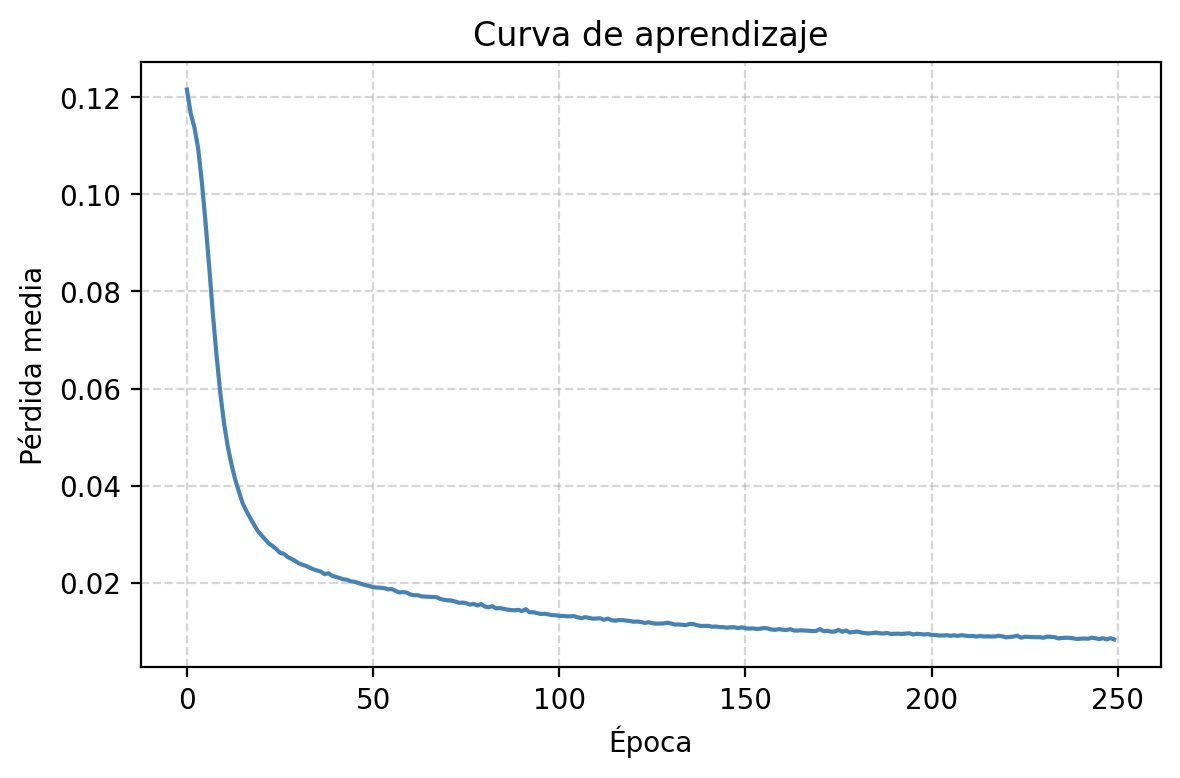

In [109]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(history_cost, color="steelblue", linewidth=1.5)
ax.set_xlabel("Época")
ax.set_ylabel("Pérdida media")
ax.set_title("Curva de aprendizaje")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [110]:
aciertos, predicciones = evaluar_clasificacion(test_samples, NUM_PUNTOS_TEST)
tasa_test=(aciertos/NUM_PUNTOS_TEST)

In [111]:
print(aciertos)

1959


In [112]:
print("tasa de acierto en test",tasa_test)

tasa de acierto en test 0.9795


In [113]:
numpuntosplot = min(1000,NUM_PUNTOS_TEST)
datos=[[test_samples[0][i],test_samples[1][i],test_samples[2][i]] for i in range(numpuntosplot)]
datos=np.array(datos).reshape(numpuntosplot,3)
labels=np.array(predicciones)[0:numpuntosplot]
fallos = 0
for i in range(numpuntosplot):
    if (labels[i] != test_samples[2][i]):
        fallos +=1
        labels[i] = 2

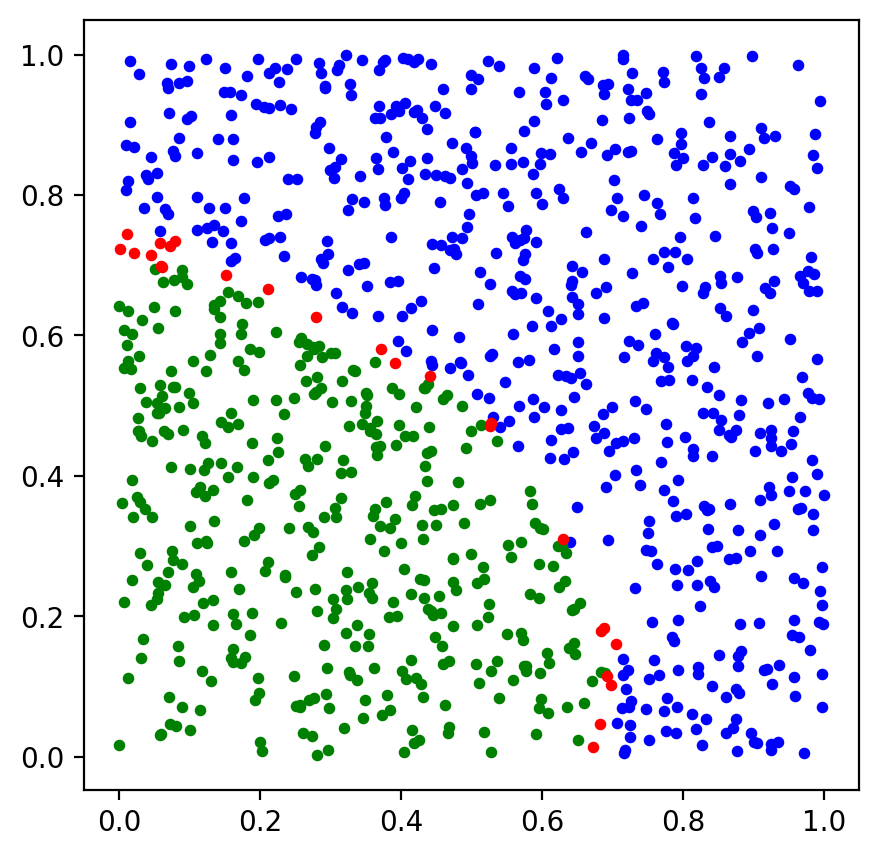

In [114]:
plot_data(datos,plabels=labels)


---

<font size="1" color="grey">
    (c) 2026 Javier García Algarra. <a href='https://www.u-tad.com'>www.u-tad.com</a> <br>
Licensed under a Creative Commons Reconocimiento 4.0 Internacional License
</font>